In [169]:
import matplotlib.pyplot as plt
import numpy as np
from em1d.physics import *
from numpy.linalg import solve
from numpy.linalg import det

In [170]:
from sympy import *
num_symbols = 5  # You can adjust this to the number of symbols you require
u = symbols('u1:{}'.format(num_symbols + 1))
h = symbols('h1:{}'.format(num_symbols))

a = symbols('a1:{}'.format(num_symbols))
b = symbols('b1:{}'.format(num_symbols))

u0,z,hi = symbols('u0, z, h_i')
ui,ui1 = symbols('u_i, u_{i+1}')

In [250]:
from sympy import series

In [251]:
lamda,k,lam0,c = symbols('\\lambda, k, \\lambda_0, c')
un2 = lam0**2 - k**2
un = sqrt(lamda**2 - k**2)
un.series(lamda,x0=lam0,n=4).subs(un2, c).removeO()

\lambda_0*(\lambda - \lambda_0)/sqrt(c) + sqrt(c)*(\lambda - \lambda_0)**3*(\lambda_0**3/(2*c**3) - \lambda_0/(2*c**2)) + sqrt(c)*(\lambda - \lambda_0)**2*(-\lambda_0**2/(2*c**2) + 1/(2*c)) + sqrt(c)

In [252]:
unoflam = lambdify((lamda, lam0,c), un.series(lamda,x0=lam0,n=6).subs(un2, c).removeO(), 'numpy')

In [253]:
unoflam

<function _lambdifygenerated(Dummy_1620, Dummy_1619, c)>

In [254]:
ei_d,ei_u,ei1_d,ei1_u = exp(-ui*(z+hi)),exp(ui*(z+hi)),exp(-ui1*z),exp(ui1*z)

TypeError: 'Expr' object is not callable

In [255]:
bnd1 = Matrix([ei_d, ei_u, -ei1_d, -ei1_u])
m1 = Matrix([bnd1.T, bnd1.T.diff(z)])
msimp = m1.subs(z,0)

In [256]:
m1

Matrix([
[     exp(-u_i*(h_i + z)),     exp(u_i*(h_i + z)),        -exp(-u_{i+1}*z),         -exp(u_{i+1}*z)],
[-u_i*exp(-u_i*(h_i + z)), u_i*exp(u_i*(h_i + z)), u_{i+1}*exp(-u_{i+1}*z), -u_{i+1}*exp(u_{i+1}*z)]])

In [257]:
msair = m1.subs(z,0).subs(hi,0)
msair

Matrix([
[   1,   1,      -1,       -1],
[-u_i, u_i, u_{i+1}, -u_{i+1}]])

In [258]:
ampVec = Matrix([a[0], b[0], a[1], b[1]])
eqset = msair*ampVec
eq1 = Eq(eqset[0],0)
eq2 = Eq(eqset[1],0)
ans = solve([eq1,eq2],a[0],b[0])

In [259]:
ans[a[0]]

(a2*u_i + a2*u_{i+1} + b2*u_i - b2*u_{i+1})/(2*u_i)

In [260]:
ans[b[0]]

(a2*u_i - a2*u_{i+1} + b2*u_i + b2*u_{i+1})/(2*u_i)

In [261]:
import torch

In [262]:
thick

tensor([[ 0],
        [20],
        [30],
        [40]], dtype=torch.int32)

In [347]:
sigma = np.array([0.02, 0.1, 0.1, 0.4])
thick = np.arange(1, len(sigma)+1)*10

sigma = torch.from_numpy(sigma)[:, None]
thick = torch.from_numpy(thick)[:, None]

thick[0] = 0.

mu = torch.ones_like(sigma)*mu0
epsilon = torch.ones_like(sigma)*epsilon0
#omega = torch.logspace(1, 6, 201)[None, :, None]
omega = 2*torch.pi*10
wave_length=torch.logspace(-5, -1, 301)[None,  :]
bottom_val = torch.tensor([1,0], dtype=torch.complex128)

In [348]:
lambda2 = wave_length**2
k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
un = torch.sqrt(lambda2 - k2)
un2 = un*1.
u0 = freespace_u0(omega, wave_length)
un1 = torch.roll(un, 1, dims=0)
un1[0] = u0*1.


euh_p = torch.exp(un1*thick)

euh_m = 1./euh_p
d_un  = (un1-un2)/(2*un2)
m_un  = (un1+un2)/(2*un2)

propmat = torch.zeros((2,2)+m_un.shape, dtype=torch.complex128)
propmat[0, 0] =  m_un*euh_p
propmat[0, 1] =  d_un*euh_p
propmat[1, 0] =  d_un*euh_m
propmat[1, 1] =  m_un*euh_m

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0] = 1
# answer = torch.einsum('ij..., j...->i...', reduced_mat, answer)
for i in range(len(a)-1,-1,-1):
    if torch.all(un1[i] != un2[i]):
        answer = torch.einsum('ij...,j...->i...', propmat[..., i,:], answer)
rte1 = torch.squeeze(answer[1]/answer[0])

In [307]:
lam0 = 1e-2
k0 = calc_wavenumber(sigma[0], torch.tensor(omega))
c0 = lam0**2 - k0**2
# lamda,k,lam0,c = symbols('\\lambda, k, \\lambda_0, c')
# un2 = lam0**2 - k**2
# un = sqrt(lamda**2 - k**2)
# un.series(lamda,x0=lam0,n=4).subs(un2, c)

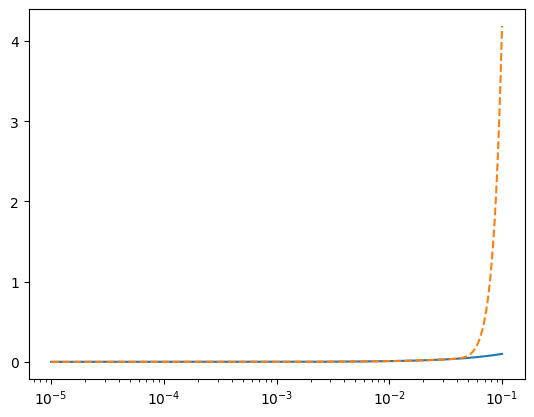

In [266]:
un_real = torch.sqrt(wave_length**2 - k0**2).squeeze()
un_tayl = unoflam(wave_length, lam0, c0).squeeze()
plt.figure()
plt.semilogx(wave_length.squeeze(), torch.abs(un_real))
plt.semilogx(wave_length.squeeze(), torch.abs(un_tayl), '--')

In [349]:
surfMat = propmat[...,0,:]
invsurfMat = torch.zeros_like(surfMat)
invsurfMat[0,0] = surfMat[1,1]
invsurfMat[1,1] = surfMat[0,0]
invsurfMat[0,1] = -surfMat[1,0]
invsurfMat[1,0] = -surfMat[0,1]
invsurfMat /= surfMat[0,0]*surfMat[1,1] - surfMat[0,1]*surfMat[1,0]
invsurfMat.imag = -invsurfMat.imag

In [350]:
rte = torch.squeeze(refl_transverse_electric(sigma, thick[1:], omega, wave_length))
rte0 = torch.stack([torch.ones_like(rte), torch.ones_like(rte)*rte[100]], dim=0)

In [361]:
lay1 = torch.einsum('ij,j...->i...', invsurfMat[..., 100], rte0)
rteEst = torch.einsum('ij...,j...->i...', surfMat, lay1)
rteEst = rteEst[1]/rteEst[0]#.imag+1j*rteEst[1].real

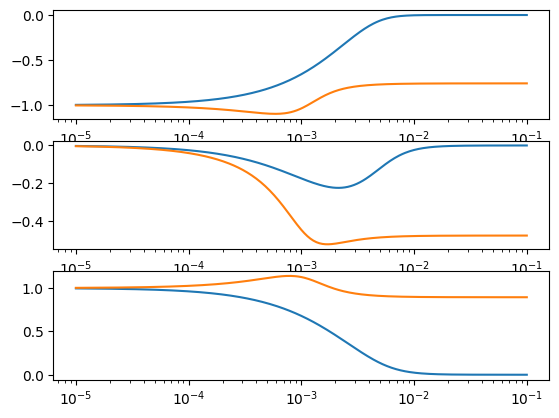

In [362]:
rte = torch.squeeze(refl_transverse_electric(sigma, thick[1:], omega, wave_length))
fig,axs = plt.subplots(3,1)
axs[0].semilogx(wave_length.squeeze(), rte.real,  label='PyTorch')
axs[0].semilogx(wave_length.squeeze(), rteEst.real, label='PyTorch')

axs[1].semilogx(wave_length.squeeze(), rte.imag,  label='PyTorch')
axs[1].semilogx(wave_length.squeeze(), rteEst.imag, label='PyTorch')

axs[2].semilogx(wave_length.squeeze(), torch.abs(rte),  label='PyTorch')
axs[2].semilogx(wave_length.squeeze(), torch.abs(rteEst), label='PyTorch')